# Model Development — Monte Carlo Simulation
**Student:** Mathonsi Mphikeleli Mbongiseni (28574249) · UNISA MCom Quantitative Management

Assets: MSFT, AAPL, NVDA, IBM, CSCO, JPM, BAC, C · Period: Jan 2010 – Dec 2025

This notebook is a companion to `Model Development.ipynb`. That notebook converts each model's volatility forecast into a VaR figure with a closed-form Student-t quantile. Here the same volatility forecasts (GARCH, EGARCH, GJR-GARCH and the Hybrid ML-GARCH refinement) are pushed through a Monte Carlo engine instead: for every test day, thousands of one-day-ahead returns are simulated and VaR and Expected Shortfall are read directly from the simulated distribution. The results are compared, day by day and through the Kupiec and Christoffersen backtests, with the closed-form numbers produced by the existing pipeline. Nothing in the existing notebooks, models or result files is modified: the baseline is read, and every new output carries an `mc_` prefix.

## 1. Setup

In [1]:
import warnings
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from pathlib import Path
from scipy import stats
from arch import arch_model
from arch.univariate import StudentsT

warnings.filterwarnings('ignore')
pd.set_option('display.float_format', '{:.6f}'.format)

ROOT        = Path(r'e:\Academic & Research\Msc in Quantitative Management\Research Codes')
DATA_DIR    = ROOT / 'data'
FIGURES_DIR = ROOT / 'figures'
TABLES_DIR  = ROOT / 'tables'
MODELS_DIR  = ROOT / 'models'
RESULTS_DIR = ROOT / 'results'

plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 10,
})

STOCKS       = ['AAPL', 'BAC', 'C', 'CSCO', 'IBM', 'JPM', 'MSFT', 'NVDA']
TRADING_DAYS = 252
CONF_LEVELS  = [0.95, 0.99]
REFIT_FREQ   = 63
TRAIN_FRAC   = 0.80
N_SIM        = 10_000
HORIZON      = 10
SEED         = 42
MODEL_NAMES  = ['GARCH', 'EGARCH', 'GJR-GARCH', 'Hybrid']
COLORS       = {'GARCH': '#D65F5F', 'EGARCH': '#4878CF', 'GJR-GARCH': '#6ACC65', 'Hybrid': '#8172B2'}

rng = np.random.default_rng(SEED)

def seeded_arch_model(y, vol, o, seed):
    # arch draws simulated innovations from the distribution object, not from the random_state
    # argument of forecast(), so the seed has to be attached to the distribution to be reproducible
    am = arch_model(y, mean='Constant', vol=vol, p=1, o=o, q=1, dist='t')
    am.distribution = StudentsT(seed=np.random.RandomState(seed))
    return am


## 2. Baseline from the Existing Pipeline

The out-of-sample volatility forecasts, VaR series and backtest table saved by `Model Development.ipynb` are loaded read-only and treated as the reference. Only the Student-t degrees of freedom of each GARCH-family model are refitted here (they are deterministic and were not saved with the forecasts), so that the closed-form VaR can be rebuilt and checked against the saved figures before any simulation is run. The volatility forecasts themselves are taken from the saved file rather than recomputed: EGARCH multi-step forecasts in `arch` come from an internal simulation that is not reproducible from run to run, and using the saved series guarantees that the closed-form and Monte Carlo VaR are built on identical inputs. The `arch` simulations run later in this notebook (Section 7) are seeded through the distribution object, which is what makes them reproducible.

In [2]:
ret         = pd.read_csv(DATA_DIR / 'log_returns_clean.csv', index_col='Date', parse_dates=True)
portfolio   = ret[STOCKS].mean(axis=1).rename('PORTFOLIO')
returns_pct = portfolio * 100

split_idx = int(len(portfolio) * TRAIN_FRAC)
train_idx = portfolio.index[:split_idx]
test_idx  = portfolio.index[split_idx:]

baseline    = pd.read_csv(RESULTS_DIR / 'oos_predictions.csv', index_col=0, parse_dates=True)
baseline_bt = pd.read_csv(RESULTS_DIR / 'var_backtest_summary.csv')
with open(MODELS_DIR / 'hybrid_var_results.pkl', 'rb') as f:
    hybrid_meta = pickle.load(f)

EVAL_IDX = baseline.index
actual   = baseline['actual_next_ret']
sigma    = {m: baseline[f'{m}_sigma'] for m in MODEL_NAMES}
mu_eval  = portfolio.rolling(TRADING_DAYS).mean().reindex(EVAL_IDX)

print(f"Evaluation window : {EVAL_IDX.min().date()} to {EVAL_IDX.max().date()}  (n={len(EVAL_IDX)})")
print(f"Saved forecast columns: {[c for c in baseline.columns if c.endswith('_sigma')]}")


Evaluation window : 2022-10-14 to 2025-12-29  (n=804)
Saved forecast columns: ['GARCH_sigma', 'EGARCH_sigma', 'GJR-GARCH_sigma', 'Hybrid_sigma']


In [3]:
SPECS = {'GARCH': ('GARCH', 0), 'EGARCH': ('EGARCH', 1), 'GJR-GARCH': ('GARCH', 1)}

def fitted_nu_path(vol, o, refit_freq=REFIT_FREQ):
    nu = pd.Series(index=test_idx, dtype=float)
    pos0 = len(train_idx)
    base = returns_pct.index.get_loc(train_idx[0])
    for start in range(0, len(test_idx), refit_freq):
        end    = min(start + refit_freq, len(test_idx))
        window = returns_pct.index[base: base + pos0 + start]
        res = arch_model(returns_pct.loc[window], mean='Constant', vol=vol, p=1, o=o, q=1, dist='t').fit(disp='off')
        nu.loc[test_idx[start:end]] = res.params['nu']
    return nu.reindex(EVAL_IDX)

nu_path = {m: fitted_nu_path(*SPECS[m]) for m in SPECS}
nu_path['Hybrid'] = pd.Series(hybrid_meta['student_t_dof'], index=EVAL_IDX)

print(pd.DataFrame({m: nu_path[m].describe()[['min', 'mean', 'max']] for m in MODEL_NAMES}).round(3).to_string())


        GARCH   EGARCH  GJR-GARCH   Hybrid
min  5.920000 6.081000   6.127000 4.000000
mean 6.133000 6.308000   6.352000 4.000000
max  6.398000 6.531000   6.601000 4.000000


In [4]:
def t_quantile(alpha, nu):
    return stats.t.ppf(alpha, df=nu) * np.sqrt((nu - 2) / nu)

def t_expected_shortfall(alpha, nu):
    q = stats.t.ppf(alpha, df=nu)
    es_raw = -(stats.t.pdf(q, df=nu) * (nu + q ** 2)) / (alpha * (nu - 1))
    return es_raw * np.sqrt((nu - 2) / nu)

def analytic_var(m, cl):
    return -(mu_eval + sigma[m] * t_quantile(1 - cl, nu_path[m]))

def analytic_es(m, cl):
    return -(mu_eval + sigma[m] * t_expected_shortfall(1 - cl, nu_path[m]))

worst = 0.0
for m in MODEL_NAMES:
    for cl in CONF_LEVELS:
        diff = (analytic_var(m, cl) - baseline[f'{m}_var_{int(cl * 100)}']).abs().max()
        worst = max(worst, diff)
print(f"Largest gap between rebuilt closed-form VaR and the saved VaR: {worst:.2e}")
assert worst < 1e-6, "Closed-form VaR could not be reproduced from the saved forecasts."


Largest gap between rebuilt closed-form VaR and the saved VaR: 1.22e-08


In [5]:
def kupiec_test(violations, alpha):
    T, x = len(violations), int(violations.sum())
    pi_hat = np.clip(x / T, 1e-6, 1 - 1e-6)
    ll_null = (T - x) * np.log(1 - alpha) + x * np.log(alpha)
    ll_alt  = (T - x) * np.log(1 - pi_hat) + x * np.log(pi_hat)
    lr = -2 * (ll_null - ll_alt)
    return lr, 1 - stats.chi2.cdf(lr, df=1)

def christoffersen_test(violations):
    v = np.asarray(violations).astype(int)
    n00 = n01 = n10 = n11 = 0
    for prev, cur in zip(v[:-1], v[1:]):
        n00 += prev == 0 and cur == 0
        n01 += prev == 0 and cur == 1
        n10 += prev == 1 and cur == 0
        n11 += prev == 1 and cur == 1
    pi01 = n01 / (n00 + n01) if (n00 + n01) else 0.0
    pi11 = n11 / (n10 + n11) if (n10 + n11) else 0.0
    pi   = (n01 + n11) / (n00 + n01 + n10 + n11)
    safe_log = lambda x: np.log(np.clip(x, 1e-10, 1 - 1e-10))
    ll_null = (n00 + n10) * safe_log(1 - pi) + (n01 + n11) * safe_log(pi)
    ll_alt  = n00 * safe_log(1 - pi01) + n01 * safe_log(pi01) + n10 * safe_log(1 - pi11) + n11 * safe_log(pi11)
    lr = -2 * (ll_null - ll_alt)
    return lr, 1 - stats.chi2.cdf(lr, df=1)

def es_backtest_ratio(actual, var_est, es_est):
    breach = actual < -var_est
    if breach.sum() == 0:
        return np.nan
    return (-actual[breach]).mean() / es_est[breach].mean()

def backtest_row(model, cl, method, var_est, es_est):
    v = (actual < -var_est)
    lr_pof, p_pof = kupiec_test(v, 1 - cl)
    lr_ind, p_ind = christoffersen_test(v)
    return {'Model': model, 'CL': cl, 'Method': method, 'Violations': int(v.sum()),
            'Violation Rate (%)': v.mean() * 100, 'Kupiec LR': lr_pof, 'Kupiec p': p_pof,
            'Christoffersen LR': lr_ind, 'Christoffersen p': p_ind,
            'ES Ratio': es_backtest_ratio(actual, var_est, es_est)}


## 3. Monte Carlo Engine

For each test day $t$ and model $m$, the one-day-ahead return is simulated as

$$r^{(i)}_{t+1} = \hat\mu_t + \hat\sigma_{m,t+1}\, z^{(i)}, \qquad z^{(i)} \sim \text{Student-}t_{\nu}\ \text{rescaled to unit variance},\quad i = 1,\dots,N$$

with $N = 10{,}000$ draws per day. $\hat\mu_t$ is the same trailing 252-day mean the existing pipeline uses, $\hat\sigma_{m,t+1}$ is model $m$'s saved volatility forecast, and $\nu$ is the same tail parameter the closed-form VaR uses, so any difference between the two approaches is purely Monte Carlo error. VaR at confidence $c$ is minus the empirical $(1-c)$ quantile of the simulated returns; Expected Shortfall is minus their mean below that quantile. The probability integral transform of the realised return under the simulated distribution is kept as well, for the density-calibration check in Section 8.

In [6]:
def draw_innovations(shape, nu=None, kind='t', generator=None):
    generator = rng if generator is None else generator
    if kind == 'normal':
        return generator.standard_normal(shape)
    nu = np.asarray(nu, dtype=float).reshape(-1, 1)
    return generator.standard_t(nu, size=shape) * np.sqrt((nu - 2) / nu)

def simulate_one_day(mu, sig, nu, n_sim, kind='t', generator=None):
    z = draw_innovations((len(mu), n_sim), nu, kind, generator)
    return np.asarray(mu)[:, None] + np.asarray(sig)[:, None] * z

def risk_from_simulations(sims, cl, index):
    q    = np.quantile(sims, 1 - cl, axis=1)
    tail = sims <= q[:, None]
    es   = -(np.where(tail, sims, 0.0).sum(axis=1) / tail.sum(axis=1))
    return pd.Series(-q, index=index), pd.Series(es, index=index)

QUANTILES = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
mc_var, mc_es, pit, mc_bands = {}, {}, {}, {}

for m in MODEL_NAMES:
    sims = simulate_one_day(mu_eval, sigma[m], nu_path[m].values, N_SIM)
    for cl in CONF_LEVELS:
        mc_var[(m, cl)], mc_es[(m, cl)] = risk_from_simulations(sims, cl, EVAL_IDX)
    pit[m]      = pd.Series((sims < actual.values[:, None]).mean(axis=1), index=EVAL_IDX)
    mc_bands[m] = pd.DataFrame(np.quantile(sims, QUANTILES, axis=1).T, index=EVAL_IDX, columns=QUANTILES)
    del sims

print(f"Simulated {N_SIM:,} one-day returns for each of {len(EVAL_IDX)} days and {len(MODEL_NAMES)} models "
      f"({N_SIM * len(EVAL_IDX) * len(MODEL_NAMES):,} draws in total).")


Simulated 10,000 one-day returns for each of 804 days and 4 models (32,160,000 draws in total).


### 3.1 Simulated versus closed-form VaR

In [7]:
rows = []
for m in MODEL_NAMES:
    for cl in CONF_LEVELS:
        a, s = analytic_var(m, cl), mc_var[(m, cl)]
        d = s - a
        rows.append({'Model': m, 'CL': cl,
                     'Closed-form VaR (%)': a.mean() * 100, 'Monte Carlo VaR (%)': s.mean() * 100,
                     'Mean diff (bp)': d.mean() * 1e4, 'Mean |diff| (bp)': d.abs().mean() * 1e4,
                     'Max |diff| (bp)': d.abs().max() * 1e4, 'Mean |rel. diff| (%)': (d.abs() / a).mean() * 100})

var_vs_analytic = pd.DataFrame(rows).set_index(['Model', 'CL'])
print(var_vs_analytic.round(3).to_string())
var_vs_analytic.to_csv(TABLES_DIR / 'mc_var_vs_analytic.csv')


                    Closed-form VaR (%)  Monte Carlo VaR (%)  Mean diff (bp)  Mean |diff| (bp)  Max |diff| (bp)  Mean |rel. diff| (%)
Model     CL                                                                                                                         
GARCH     0.950000             2.186000             2.185000       -0.158000          2.883000        17.510000              1.336000
          0.990000             3.581000             3.570000       -1.058000          7.170000        48.372000              1.992000
EGARCH    0.950000             1.934000             1.933000       -0.105000          2.591000        22.479000              1.358000
          0.990000             3.160000             3.156000       -0.390000          6.188000        50.307000              1.982000
GJR-GARCH 0.950000             1.982000             1.981000       -0.109000          2.613000        15.150000              1.331000
          0.990000             3.233000             3.228000  

## 4. Backtesting the Simulated VaR

The same three tests used in the existing notebook are applied to both versions of every model: the Kupiec test for unconditional coverage, the Christoffersen test for independence of violations, and the Expected Shortfall ratio. The closed-form rows are rebuilt from the saved VaR series and checked against the saved backtest table, so the comparison starts from the exact numbers already reported.

In [8]:
bt_rows = []
for m in MODEL_NAMES:
    for cl in CONF_LEVELS:
        bt_rows.append(backtest_row(m, cl, 'Closed-form', analytic_var(m, cl), analytic_es(m, cl)))
        bt_rows.append(backtest_row(m, cl, 'Monte Carlo', mc_var[(m, cl)], mc_es[(m, cl)]))
backtest_mc = pd.DataFrame(bt_rows)

saved = baseline_bt.set_index(['Model', 'CL'])['Violations']
rebuilt = backtest_mc.query("Method == 'Closed-form'").set_index(['Model', 'CL'])['Violations']
assert (saved.sort_index() == rebuilt.sort_index()).all(), "Closed-form violations differ from the saved backtest."
print("Closed-form violation counts match the saved backtest table for all 8 model/confidence pairs.\n")

view = backtest_mc.pivot_table(index=['Model', 'CL'], columns='Method',
                               values=['Violation Rate (%)', 'Kupiec p', 'Christoffersen p', 'ES Ratio'])
print(view.round(4).to_string())


Closed-form violation counts match the saved backtest table for all 8 model/confidence pairs.

                   Christoffersen p                ES Ratio                Kupiec p             Violation Rate (%)            
Method                  Closed-form Monte Carlo Closed-form Monte Carlo Closed-form Monte Carlo        Closed-form Monte Carlo
Model     CL                                                                                                                  
EGARCH    0.950000         0.031900    0.050400    1.119700    1.100200    0.121500    0.229800           3.855700    4.104500
          0.990000         0.006800    0.108500    1.059800    1.087500    0.320400    0.503300           1.368200    1.243800
GARCH     0.950000         0.043400    0.043400    1.105500    1.099700    0.008400    0.008400           3.109500    3.109500
          0.990000         0.031500    0.000800    1.151900    1.089600    0.449000    0.706200           0.746300    0.870600
GJR-GARCH 0.9500

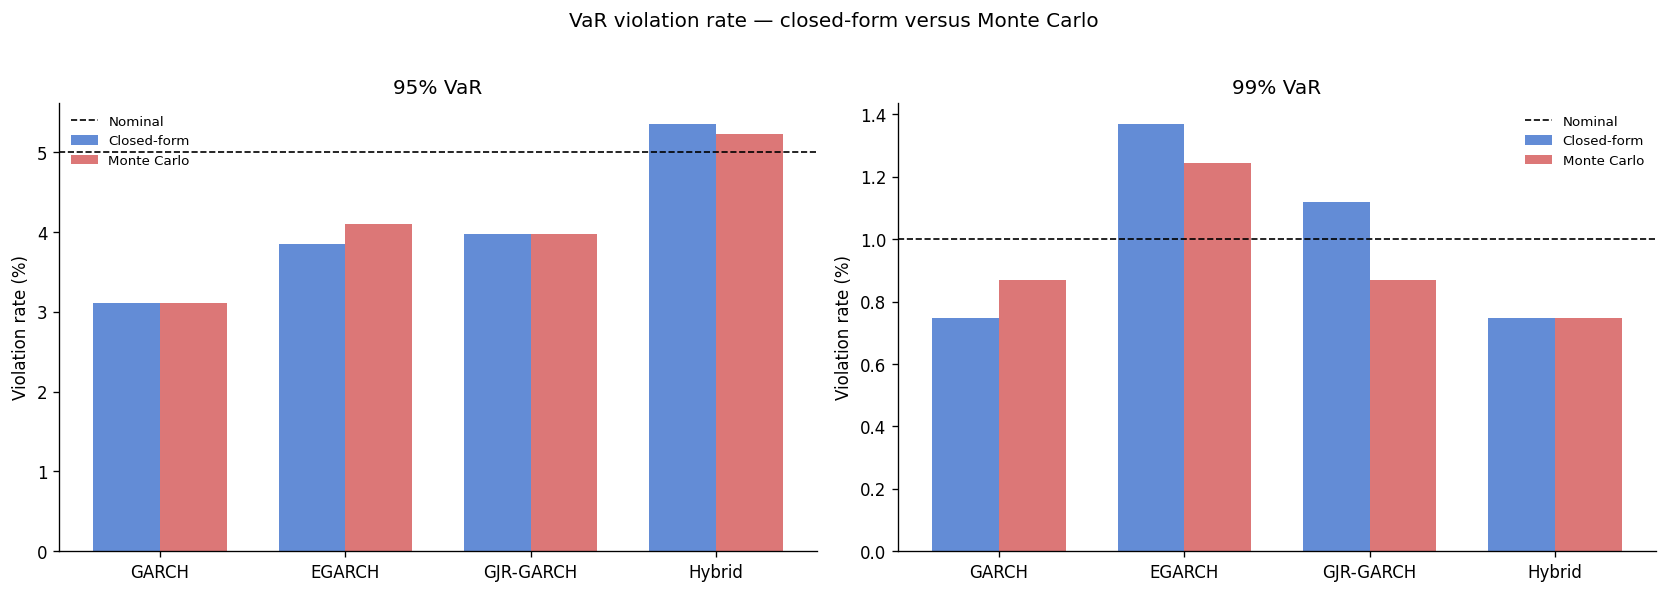

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=False)
width = 0.36
for ax, cl in zip(axes, CONF_LEVELS):
    sub = backtest_mc[backtest_mc['CL'] == cl]
    x = np.arange(len(MODEL_NAMES))
    for k, (method, color) in enumerate([('Closed-form', '#4878CF'), ('Monte Carlo', '#D65F5F')]):
        vals = [sub[(sub['Model'] == m) & (sub['Method'] == method)]['Violation Rate (%)'].iloc[0] for m in MODEL_NAMES]
        ax.bar(x + (k - 0.5) * width, vals, width, color=color, alpha=0.85, label=method)
    ax.axhline((1 - cl) * 100, color='black', ls='--', lw=1, label='Nominal')
    ax.set_xticks(x)
    ax.set_xticklabels(MODEL_NAMES)
    ax.set_ylabel('Violation rate (%)')
    ax.set_title(f'{cl:.0%} VaR')
    ax.legend(frameon=False, fontsize=8)
plt.suptitle('VaR violation rate — closed-form versus Monte Carlo', y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'mc_violation_rates.png', bbox_inches='tight')
plt.show()


## 5. How Many Simulations Are Enough?

A Monte Carlo quantile is itself an estimate, and its error shrinks only with the square root of the number of draws; the extreme quantiles that matter for VaR are the noisiest, because few draws land in the tail. To size $N$ properly, the error of the simulated VaR and Expected Shortfall is measured for a unit-variance Student-t distribution ($\nu = 6$, close to the fitted GARCH-family value) across a grid of sample sizes, using 300 independent replications at each size.

In [10]:
NU_REF     = 6.0
N_GRID     = [100, 250, 500, 1_000, 2_500, 5_000, 10_000, 25_000, 50_000, 100_000]
REPS       = 300
conv_rng   = np.random.default_rng(SEED + 1)

true_q  = {cl: float(t_quantile(1 - cl, NU_REF)) for cl in CONF_LEVELS}
true_es = {cl: float(t_expected_shortfall(1 - cl, NU_REF)) for cl in CONF_LEVELS}

conv_rows = []
for n in N_GRID:
    draws = draw_innovations((REPS, n), np.full(REPS, NU_REF), 't', conv_rng)
    for cl in CONF_LEVELS:
        q_hat  = np.quantile(draws, 1 - cl, axis=1)
        tail   = draws <= q_hat[:, None]
        es_hat = np.where(tail, draws, 0.0).sum(axis=1) / tail.sum(axis=1)
        conv_rows.append({'N': n, 'CL': cl,
                          'VaR rel. RMSE (%)': np.sqrt(np.mean(((q_hat - true_q[cl]) / true_q[cl]) ** 2)) * 100,
                          'ES rel. RMSE (%)':  np.sqrt(np.mean(((es_hat - true_es[cl]) / true_es[cl]) ** 2)) * 100})
    del draws

convergence = pd.DataFrame(conv_rows)
print(convergence.pivot(index='N', columns='CL', values=['VaR rel. RMSE (%)', 'ES rel. RMSE (%)']).round(3).to_string())
convergence.to_csv(TABLES_DIR / 'mc_convergence.csv', index=False)


       VaR rel. RMSE (%)           ES rel. RMSE (%)          
CL              0.950000  0.990000         0.950000  0.990000
N                                                            
100            15.463000 22.345000        18.318000 29.876000
250            10.200000 14.504000        11.595000 20.011000
500             6.949000 11.869000         8.413000 16.555000
1000            5.389000  7.506000         5.652000 10.298000
2500            3.299000  5.256000         4.106000  7.146000
5000            2.516000  3.508000         2.710000  4.780000
10000           1.620000  2.520000         1.942000  3.464000
25000           1.047000  1.601000         1.185000  2.133000
50000           0.751000  1.109000         0.843000  1.468000
100000          0.458000  0.821000         0.577000  1.087000


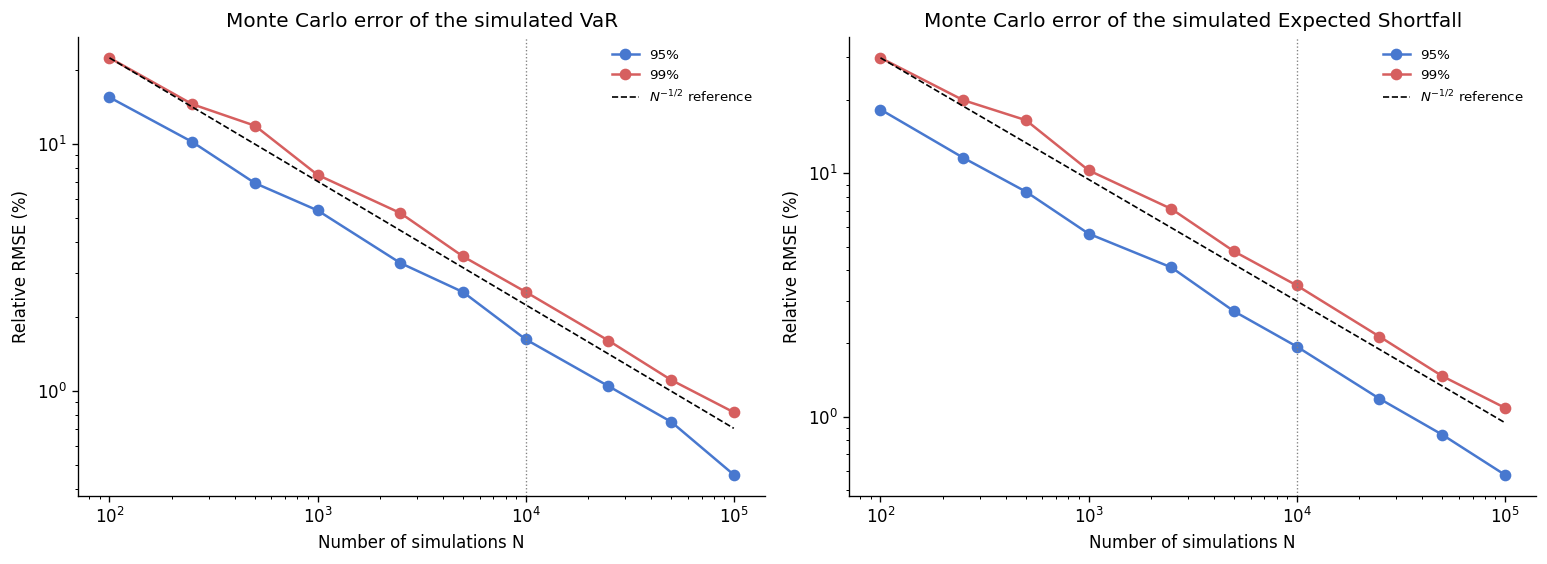

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, col, title in zip(axes, ['VaR rel. RMSE (%)', 'ES rel. RMSE (%)'], ['VaR', 'Expected Shortfall']):
    for cl, color in zip(CONF_LEVELS, ['#4878CF', '#D65F5F']):
        sub = convergence[convergence['CL'] == cl]
        ax.loglog(sub['N'], sub[col], 'o-', color=color, label=f'{cl:.0%}')
    ref = convergence[convergence['CL'] == 0.99][col].iloc[0] * np.sqrt(N_GRID[0] / np.array(N_GRID))
    ax.loglog(N_GRID, ref, 'k--', lw=1, label=r'$N^{-1/2}$ reference')
    ax.axvline(N_SIM, color='grey', lw=0.8, ls=':')
    ax.set_xlabel('Number of simulations N')
    ax.set_ylabel('Relative RMSE (%)')
    ax.set_title(f'Monte Carlo error of the simulated {title}')
    ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'mc_convergence.png', bbox_inches='tight')
plt.show()


### 5.1 Does the number of simulations change the backtest?

The same question is put to the actual test period. VaR is re-simulated for the GARCH and Hybrid models with different numbers of draws per day, in chunks to bound memory, and the resulting violation counts are compared with the closed-form count.

In [12]:
def mc_var_chunked(m, cl, n_sim, generator, chunk=100):
    out = []
    for i in range(0, len(EVAL_IDX), chunk):
        sl   = slice(i, i + chunk)
        sims = simulate_one_day(mu_eval.values[sl], sigma[m].values[sl], nu_path[m].values[sl], n_sim, 't', generator)
        out.append(-np.quantile(sims, 1 - cl, axis=1))
    return pd.Series(np.concatenate(out), index=EVAL_IDX)

sens_rng  = np.random.default_rng(SEED + 2)
sens_rows = []
for m in ['GARCH', 'Hybrid']:
    for cl in CONF_LEVELS:
        a = analytic_var(m, cl)
        sens_rows.append({'Model': m, 'CL': cl, 'N': 'closed-form', 'Violations': int((actual < -a).sum()),
                          'Kupiec p': kupiec_test(actual < -a, 1 - cl)[1], 'Mean |diff| (bp)': 0.0})
        for n in [500, 1_000, 5_000, 10_000, 50_000]:
            v = mc_var_chunked(m, cl, n, sens_rng)
            viol = actual < -v
            sens_rows.append({'Model': m, 'CL': cl, 'N': f'{n:,}', 'Violations': int(viol.sum()),
                              'Kupiec p': kupiec_test(viol, 1 - cl)[1],
                              'Mean |diff| (bp)': (v - a).abs().mean() * 1e4})

sample_size = pd.DataFrame(sens_rows).set_index(['Model', 'CL', 'N'])
print(sample_size.round(4).to_string())
sample_size.to_csv(TABLES_DIR / 'mc_sample_size_sensitivity.csv')


                             Violations  Kupiec p  Mean |diff| (bp)
Model  CL       N                                                  
GARCH  0.950000 closed-form          25  0.008400          0.000000
                500                  23  0.002600         12.860900
                1,000                27  0.023500          9.031200
                5,000                27  0.023500          4.115300
                10,000               24  0.004700          2.798800
                50,000               26  0.014300          1.336300
       0.990000 closed-form           6  0.449000          0.000000
                500                   8  0.988700         33.189600
                1,000                 8  0.988700         23.181400
                5,000                 5  0.246700         10.621800
                10,000                6  0.449000          7.223400
                50,000                6  0.449000          3.251100
Hybrid 0.950000 closed-form          43  0.65400

## 6. Sensitivity to the Innovation Distribution

Simulation makes it cheap to change the assumed distribution of shocks and see what happens to the backtest. This matters for the comparison in the existing notebook: the GARCH-family models translate volatility into VaR with their own fitted degrees of freedom (roughly 6), while the Hybrid model uses a flat $\nu = 4$ (the floor of the kurtosis-based rule). A lower $\nu$ shrinks the 95% quantile multiplier and inflates the 99% one, so part of any violation-rate difference between models can come from the tail assumption rather than the volatility forecast. Three settings are run for every model: the assumption used in the existing pipeline, one common Student-t with $\nu$ equal to the average fitted GARCH-family value, and a Normal benchmark.

In [13]:
nu_common = pd.concat([nu_path[m] for m in SPECS], axis=1).mean(axis=1)
print(f"Common tail parameter: mean nu = {nu_common.mean():.3f}   (Hybrid pipeline nu = {nu_path['Hybrid'].iloc[0]:.1f})")

q95 = {'nu=4': float(t_quantile(0.05, 4.0)), f'nu={nu_common.mean():.2f}': float(t_quantile(0.05, nu_common.mean())),
       'Normal': float(stats.norm.ppf(0.05))}
q99 = {'nu=4': float(t_quantile(0.01, 4.0)), f'nu={nu_common.mean():.2f}': float(t_quantile(0.01, nu_common.mean())),
       'Normal': float(stats.norm.ppf(0.01))}
print(pd.DataFrame({'95% quantile': q95, '99% quantile': q99}).round(4).to_string())


Common tail parameter: mean nu = 6.264   (Hybrid pipeline nu = 4.0)
         95% quantile  99% quantile
nu=4        -1.507400     -2.649500
nu=6.26     -1.591200     -2.556700
Normal      -1.644900     -2.326300


In [14]:
scenario_rng = np.random.default_rng(SEED + 3)
scenarios = {
    'Existing pipeline': None,
    'Common Student-t':  ('t', nu_common.values),
    'Normal':            ('normal', None),
}

tail_rows = []
for scen, spec in scenarios.items():
    for m in MODEL_NAMES:
        if spec is None:
            var_by_cl = {cl: mc_var[(m, cl)] for cl in CONF_LEVELS}
            es_by_cl  = {cl: mc_es[(m, cl)] for cl in CONF_LEVELS}
        else:
            sims = simulate_one_day(mu_eval, sigma[m], spec[1], N_SIM, spec[0], scenario_rng)
            var_by_cl, es_by_cl = {}, {}
            for cl in CONF_LEVELS:
                var_by_cl[cl], es_by_cl[cl] = risk_from_simulations(sims, cl, EVAL_IDX)
            del sims
        for cl in CONF_LEVELS:
            row = backtest_row(m, cl, scen, var_by_cl[cl], es_by_cl[cl])
            tail_rows.append(row)

tail_sensitivity = pd.DataFrame(tail_rows)
for cols in (['Violation Rate (%)', 'Kupiec p'], ['Christoffersen p', 'ES Ratio']):
    table = tail_sensitivity.pivot_table(index=['CL', 'Model'], columns='Method', values=cols)
    print(table[[(c, s) for c in cols for s in scenarios]].round(3).to_string(), "\n")
tail_sensitivity.to_csv(TABLES_DIR / 'mc_tail_assumption_comparison.csv', index=False)


                   Violation Rate (%)                                    Kupiec p                          
Method              Existing pipeline Common Student-t   Normal Existing pipeline Common Student-t   Normal
CL       Model                                                                                             
0.950000 EGARCH              4.104000         4.104000 3.731000          0.230000         0.230000 0.085000
         GARCH               3.109000         3.234000 2.736000          0.008000         0.014000 0.001000
         GJR-GARCH           3.980000         3.980000 3.731000          0.170000         0.170000 0.085000
         Hybrid              5.224000         4.478000 4.353000          0.772000         0.489000 0.390000
0.990000 EGARCH              1.244000         1.119000 1.617000          0.503000         0.738000 0.107000
         GARCH               0.871000         0.871000 1.244000          0.706000         0.706000 0.503000
         GJR-GARCH          

## 7. Ten-Day Horizon: Path Simulation versus the Square-Root-of-Time Rule

For a one-day horizon the closed-form and simulated VaR describe the same distribution. Over longer horizons they do not: a GARCH variance evolves with the shocks along the way, so the distribution of a ten-day return is not a rescaled one-day distribution. The regulatory square-root-of-time rule ignores this, while a Monte Carlo simulation of the full variance path captures it. For each GARCH-family model the model is refitted at every tenth test day (non-overlapping windows), ten-day return paths are simulated with `arch`, and the simulated ten-day VaR is compared with $\sqrt{10}$ times the closed-form one-day figure and with the realised ten-day return. The Hybrid model is left out: the LSTM is a one-step-ahead refinement, and a multi-step forecast would require feeding its own predictions back in recursively, which is outside the scope of this notebook.

In [15]:
all_pos  = {d: i for i, d in enumerate(portfolio.index)}
origins  = [d for d in test_idx[::HORIZON] if all_pos[d] + HORIZON < len(portfolio)]
print(f"{len(origins)} non-overlapping {HORIZON}-day windows, first origin {origins[0].date()}, last {origins[-1].date()}")

multi_rows = []
for m, (vol, o) in SPECS.items():
    for d in origins:
        p   = all_pos[d]
        res = seeded_arch_model(returns_pct.iloc[:p + 1], vol, o, SEED + p).fit(disp='off')
        fc  = res.forecast(horizon=HORIZON, method='simulation', simulations=N_SIM, reindex=False)
        cum_sim  = fc.simulations.values[0].sum(axis=1) / 100
        sigma1   = np.sqrt(fc.variance.values[0][0]) / 100
        nu_, mu_ = res.params['nu'], res.params['mu'] / 100
        realised = portfolio.iloc[p + 1: p + 1 + HORIZON].sum()
        for cl in CONF_LEVELS:
            multi_rows.append({
                'Model': m, 'Origin': d, 'CL': cl, 'Realised': realised,
                'VaR Monte Carlo': -np.quantile(cum_sim, 1 - cl),
                'VaR sqrt-time':   -(HORIZON * mu_ + np.sqrt(HORIZON) * sigma1 * t_quantile(1 - cl, nu_)),
            })

multiday = pd.DataFrame(multi_rows)
print(f"Simulated {len(multiday) // 2} model-window pairs with {N_SIM:,} paths each.")


80 non-overlapping 10-day windows, first origin 2022-10-14, last 2025-12-09


Simulated 240 model-window pairs with 10,000 paths each.


In [16]:
summary_rows = []
for (m, cl), g in multiday.groupby(['Model', 'CL']):
    v_mc = g['Realised'] < -g['VaR Monte Carlo']
    v_sq = g['Realised'] < -g['VaR sqrt-time']
    summary_rows.append({'Model': m, 'CL': cl, 'Windows': len(g),
                         'Mean VaR MC (%)': g['VaR Monte Carlo'].mean() * 100,
                         'Mean VaR sqrt-time (%)': g['VaR sqrt-time'].mean() * 100,
                         'MC / sqrt-time': (g['VaR Monte Carlo'] / g['VaR sqrt-time']).mean(),
                         'Violations MC': int(v_mc.sum()), 'Violations sqrt-time': int(v_sq.sum()),
                         'Expected': round(len(g) * (1 - cl), 1)})
multiday_summary = pd.DataFrame(summary_rows).set_index(['Model', 'CL'])
print(multiday_summary.round(3).to_string())


                    Windows  Mean VaR MC (%)  Mean VaR sqrt-time (%)  MC / sqrt-time  Violations MC  Violations sqrt-time  Expected
Model     CL                                                                                                                       
EGARCH    0.950000       80         5.547000                4.908000        1.154000              3                     3  4.000000
          0.990000       80         9.810000                8.428000        1.186000              1                     1  0.800000
GARCH     0.950000       80         5.029000                4.838000        1.056000              4                     4  4.000000
          0.990000       80         8.710000                8.558000        1.031000              2                     2  0.800000
GJR-GARCH 0.950000       80         5.382000                4.881000        1.127000              3                     4  4.000000
          0.990000       80         9.707000                8.419000        

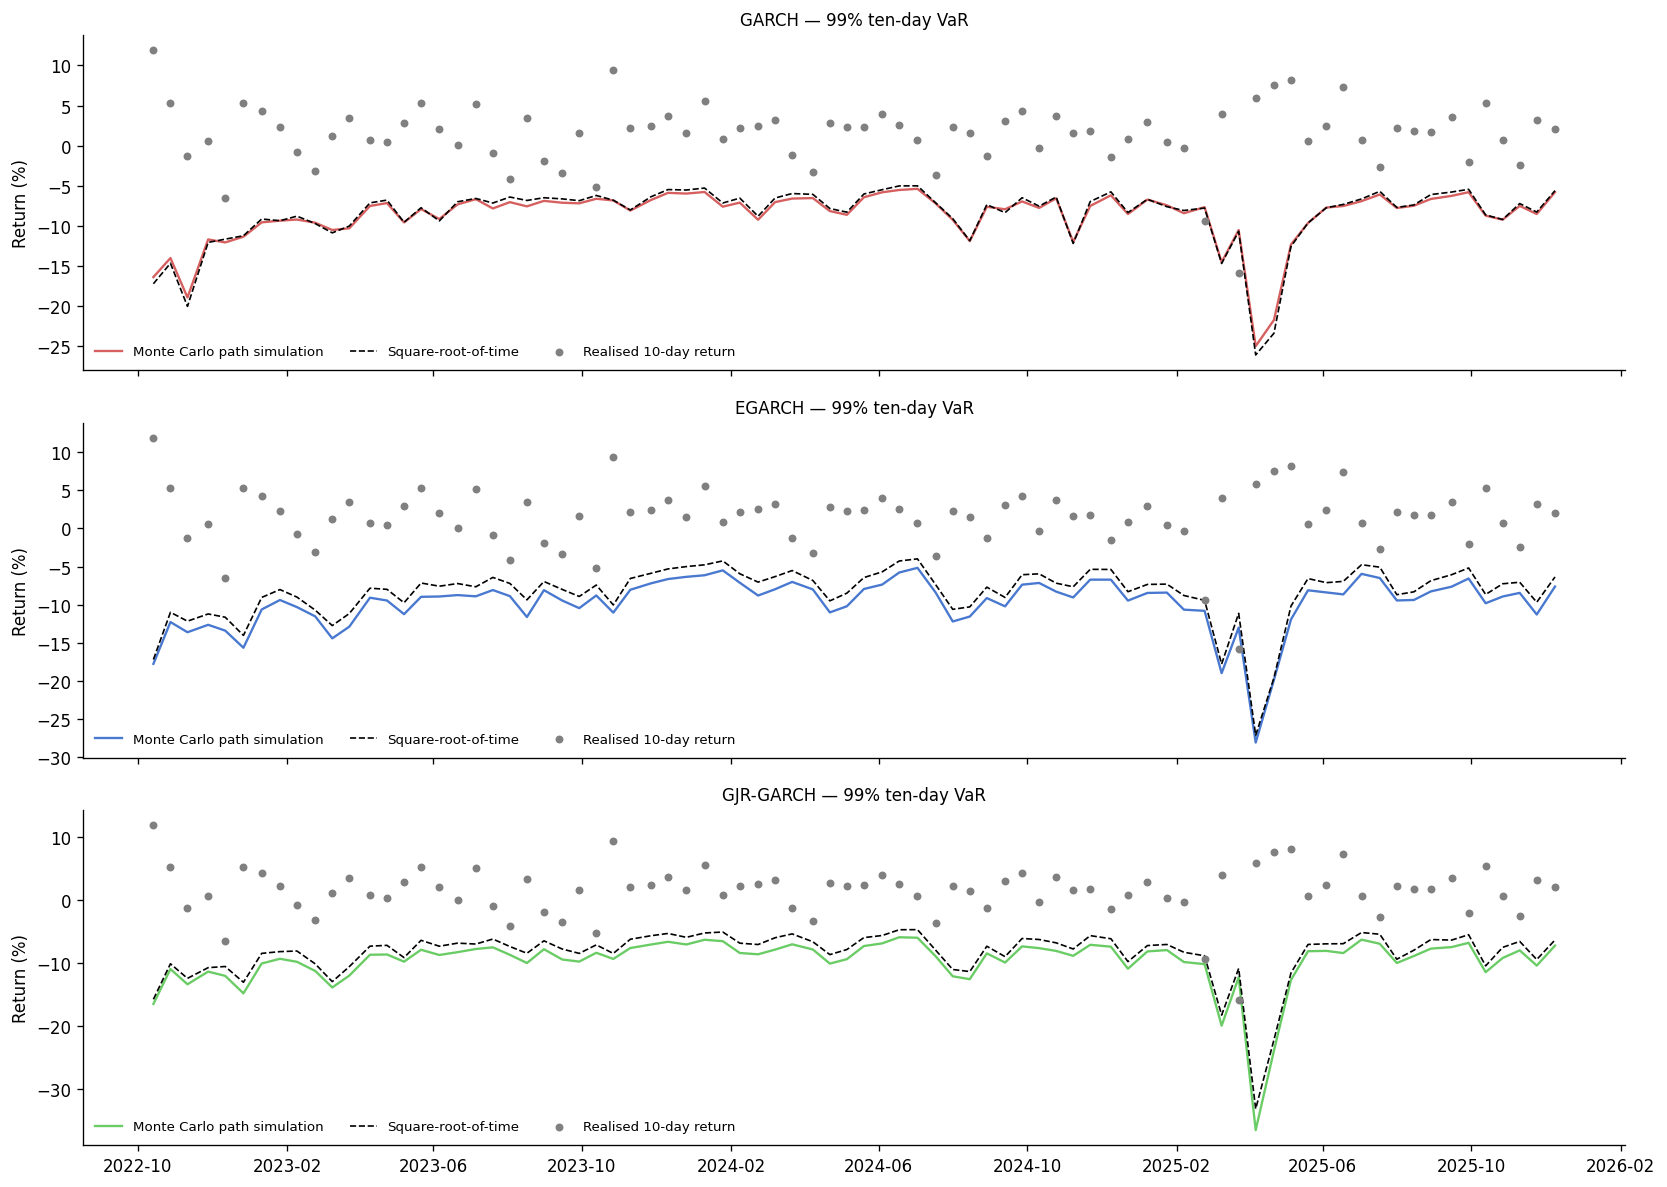

In [17]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for ax, m in zip(axes, SPECS):
    g = multiday[(multiday['Model'] == m) & (multiday['CL'] == 0.99)].set_index('Origin')
    ax.plot(g.index, -g['VaR Monte Carlo'] * 100, color=COLORS[m], lw=1.4, label='Monte Carlo path simulation')
    ax.plot(g.index, -g['VaR sqrt-time'] * 100, color='black', lw=1.0, ls='--', label='Square-root-of-time')
    ax.scatter(g.index, g['Realised'] * 100, s=14, color='grey', zorder=3, label='Realised 10-day return')
    ax.set_title(f'{m} — 99% ten-day VaR', fontsize=10)
    ax.set_ylabel('Return (%)')
    ax.legend(frameon=False, fontsize=8, ncol=3, loc='lower left')
axes[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=4))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'mc_multiday_var.png', bbox_inches='tight')
plt.show()


## 8. Density Calibration: Probability Integral Transform

VaR only tests one quantile at a time. The probability integral transform (PIT) checks the whole predictive distribution: if the simulated distribution for day $t+1$ is correct, the fraction of simulated returns falling below the realised return is uniform on $[0,1]$. A hump in the middle means the model is too wide (over-dispersed); mass piling up in the tails means it is too narrow. A Kolmogorov–Smirnov test against the uniform distribution is reported alongside; since PIT values from a volatility model are not guaranteed to be independent, the p-values are indicative rather than exact.

In [18]:
pit_rows = []
for m in MODEL_NAMES:
    ks = stats.kstest(pit[m], 'uniform')
    pit_rows.append({'Model': m, 'KS statistic': ks.statistic, 'KS p-value': ks.pvalue,
                     'PIT < 5% (share)': (pit[m] < 0.05).mean(), 'PIT > 95% (share)': (pit[m] > 0.95).mean(),
                     'PIT < 1% (share)': (pit[m] < 0.01).mean(), 'PIT > 99% (share)': (pit[m] > 0.99).mean()})
pit_tests = pd.DataFrame(pit_rows).set_index('Model')
print(pit_tests.round(4).to_string())
pit_tests.to_csv(TABLES_DIR / 'mc_pit_ks_tests.csv')


           KS statistic  KS p-value  PIT < 5% (share)  PIT > 95% (share)  PIT < 1% (share)  PIT > 99% (share)
Model                                                                                                        
GARCH          0.065900    0.001800          0.031100           0.028600          0.007500           0.006200
EGARCH         0.048500    0.044000          0.041000           0.037300          0.012400           0.006200
GJR-GARCH      0.052600    0.022400          0.039800           0.034800          0.008700           0.006200
Hybrid         0.039900    0.149600          0.052200           0.038600          0.007500           0.005000


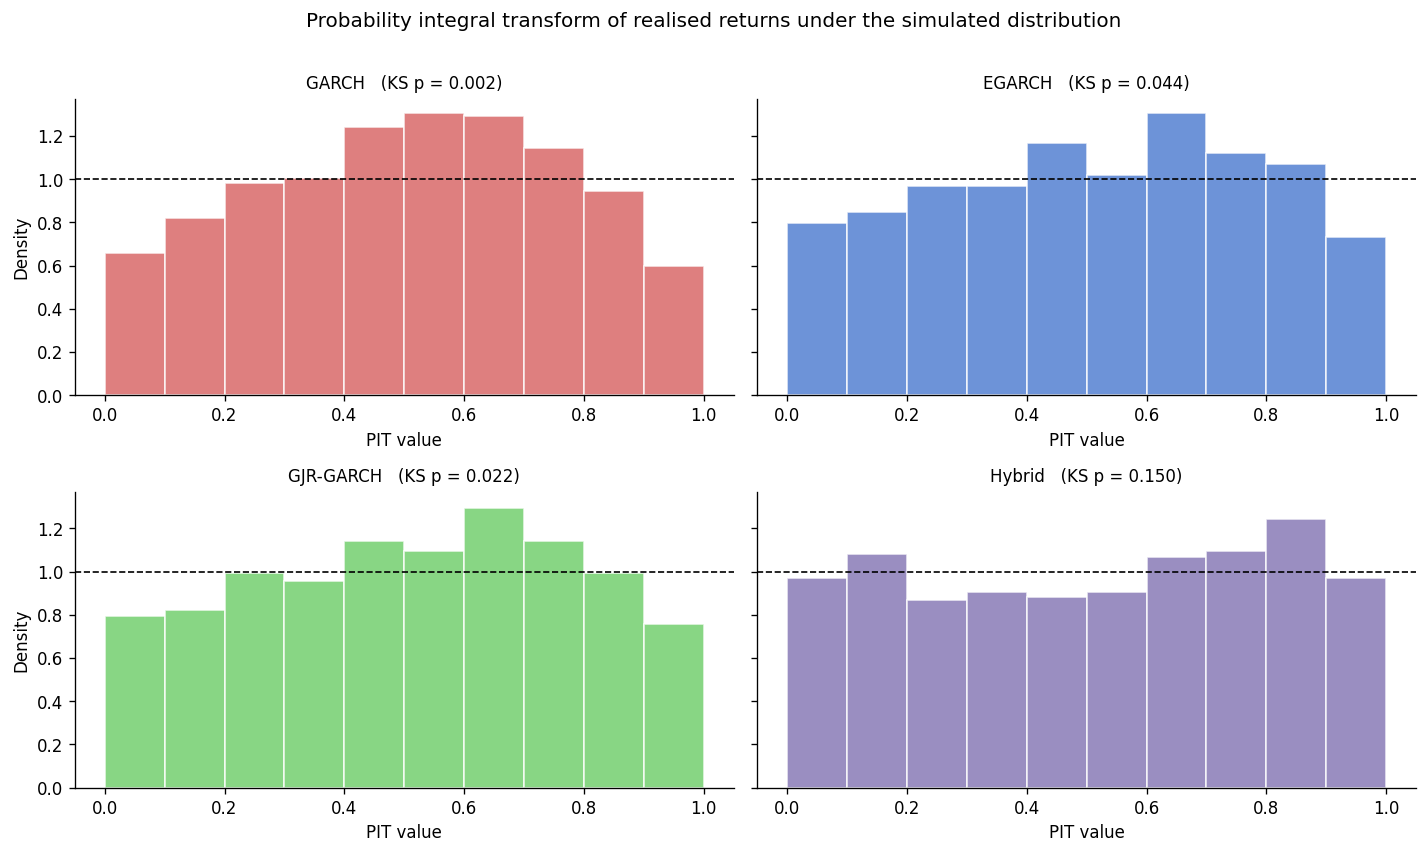

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey=True)
for ax, m in zip(axes.flatten(), MODEL_NAMES):
    ax.hist(pit[m], bins=10, range=(0, 1), density=True, color=COLORS[m], alpha=0.8, edgecolor='white')
    ax.axhline(1.0, color='black', ls='--', lw=1)
    ax.set_title(f"{m}   (KS p = {pit_tests.loc[m, 'KS p-value']:.3f})", fontsize=10)
    ax.set_xlabel('PIT value')
axes[0, 0].set_ylabel('Density')
axes[1, 0].set_ylabel('Density')
plt.suptitle('Probability integral transform of realised returns under the simulated distribution', y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'mc_pit_histograms.png', bbox_inches='tight')
plt.show()


## 9. Simulated Distributions in Pictures

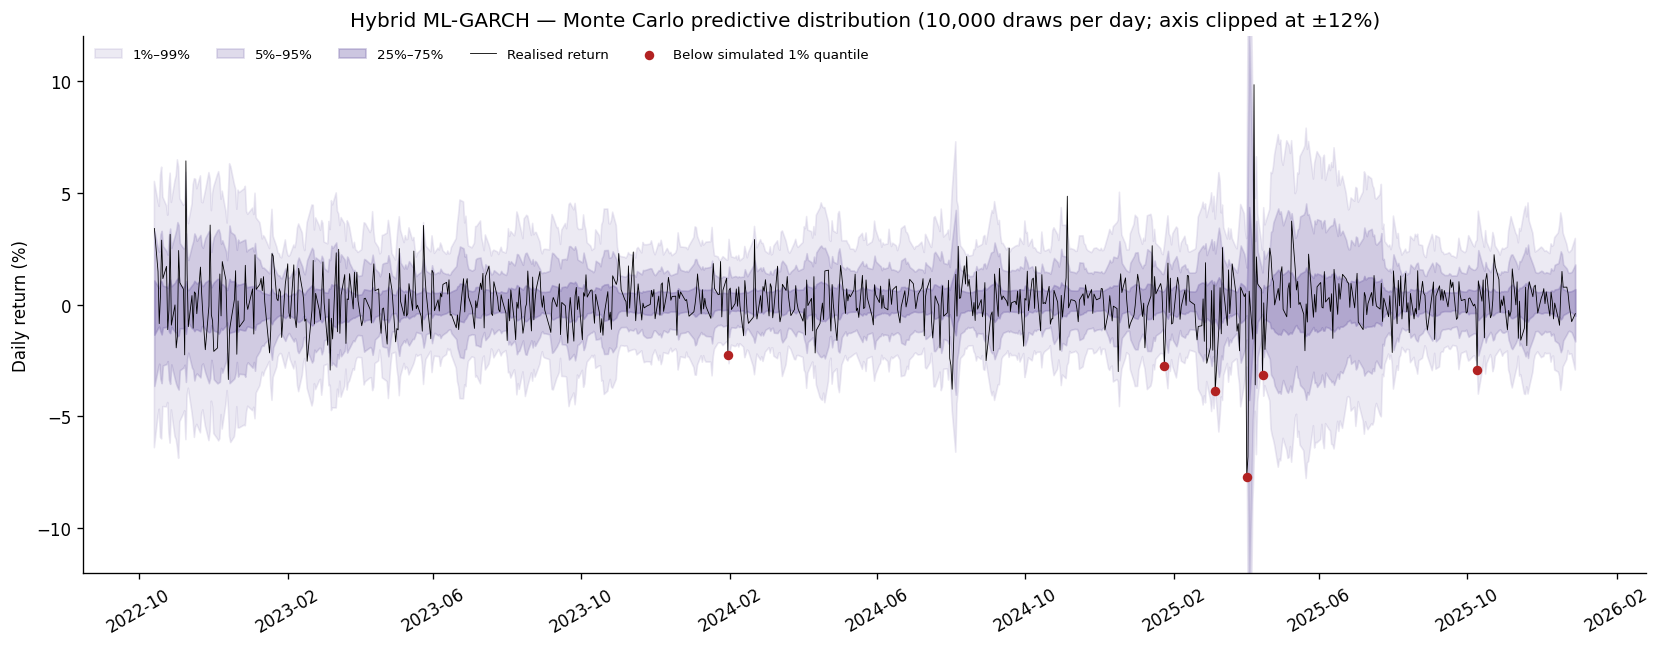

In [20]:
fig, ax = plt.subplots(figsize=(14, 5.5))
bands = mc_bands['Hybrid'] * 100
ax.fill_between(EVAL_IDX, bands[0.01], bands[0.99], color='#8172B2', alpha=0.15, label='1%–99%')
ax.fill_between(EVAL_IDX, bands[0.05], bands[0.95], color='#8172B2', alpha=0.25, label='5%–95%')
ax.fill_between(EVAL_IDX, bands[0.25], bands[0.75], color='#8172B2', alpha=0.40, label='25%–75%')
ax.plot(EVAL_IDX, actual * 100, color='black', lw=0.5, label='Realised return')
breach = actual * 100 < bands[0.01]
ax.scatter(EVAL_IDX[breach], (actual * 100)[breach], color='firebrick', s=22, zorder=5, label='Below simulated 1% quantile')
ax.set_ylim(-12, 12)
ax.set_ylabel('Daily return (%)')
ax.set_title('Hybrid ML-GARCH — Monte Carlo predictive distribution (10,000 draws per day; axis clipped at ±12%)')
ax.legend(frameon=False, fontsize=8, ncol=5)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'mc_fan_chart_hybrid.png', bbox_inches='tight')
plt.show()


Largest one-day loss in the test period: -7.71% (forecast made at close of 2025-04-02)


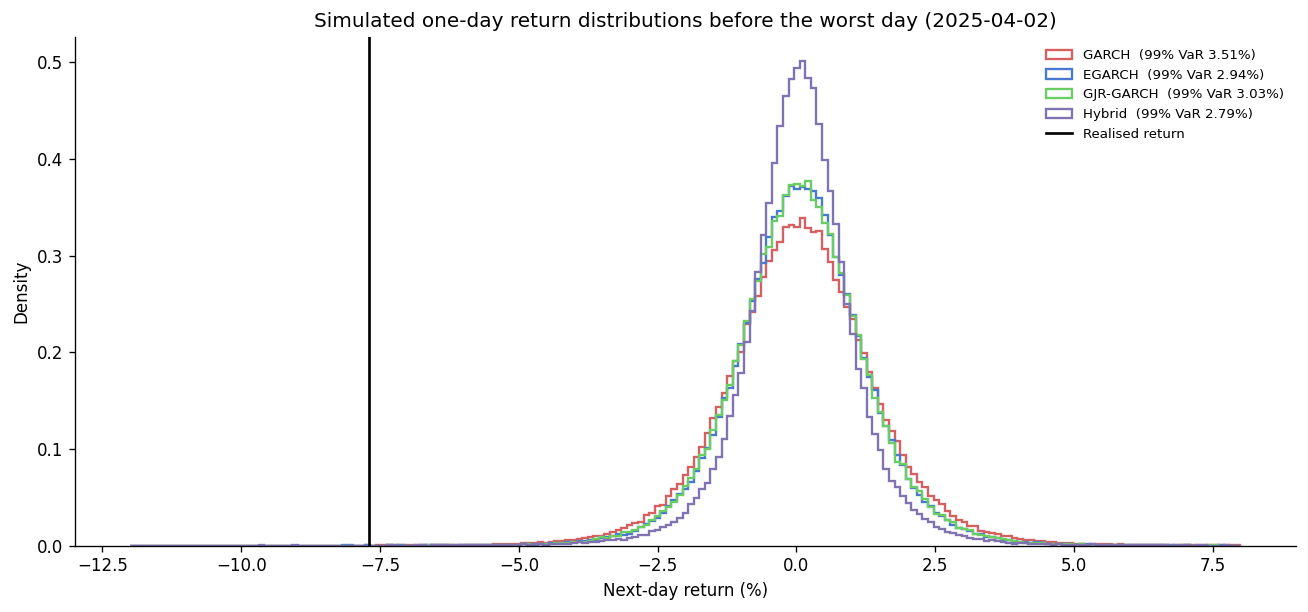

In [21]:
stress_day = actual.idxmin()
pos = EVAL_IDX.get_loc(stress_day)
stress_rng = np.random.default_rng(SEED + 4)
print(f"Largest one-day loss in the test period: {actual.loc[stress_day] * 100:.2f}% (forecast made at close of {stress_day.date()})")

fig, ax = plt.subplots(figsize=(11, 5.2))
for m in MODEL_NAMES:
    sims = simulate_one_day(mu_eval.values[pos:pos + 1], sigma[m].values[pos:pos + 1],
                            nu_path[m].values[pos:pos + 1], 200_000, 't', stress_rng)[0] * 100
    ax.hist(sims, bins=np.linspace(-12, 8, 200), density=True, histtype='step', lw=1.4, color=COLORS[m],
            label=f"{m}  (99% VaR {mc_var[(m, 0.99)].iloc[pos] * 100:.2f}%)")
ax.axvline(actual.loc[stress_day] * 100, color='black', lw=1.6, label='Realised return')
ax.set_xlabel('Next-day return (%)')
ax.set_ylabel('Density')
ax.set_title(f'Simulated one-day return distributions before the worst day ({stress_day.date()})')
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'mc_stress_day_distributions.png', bbox_inches='tight')
plt.show()


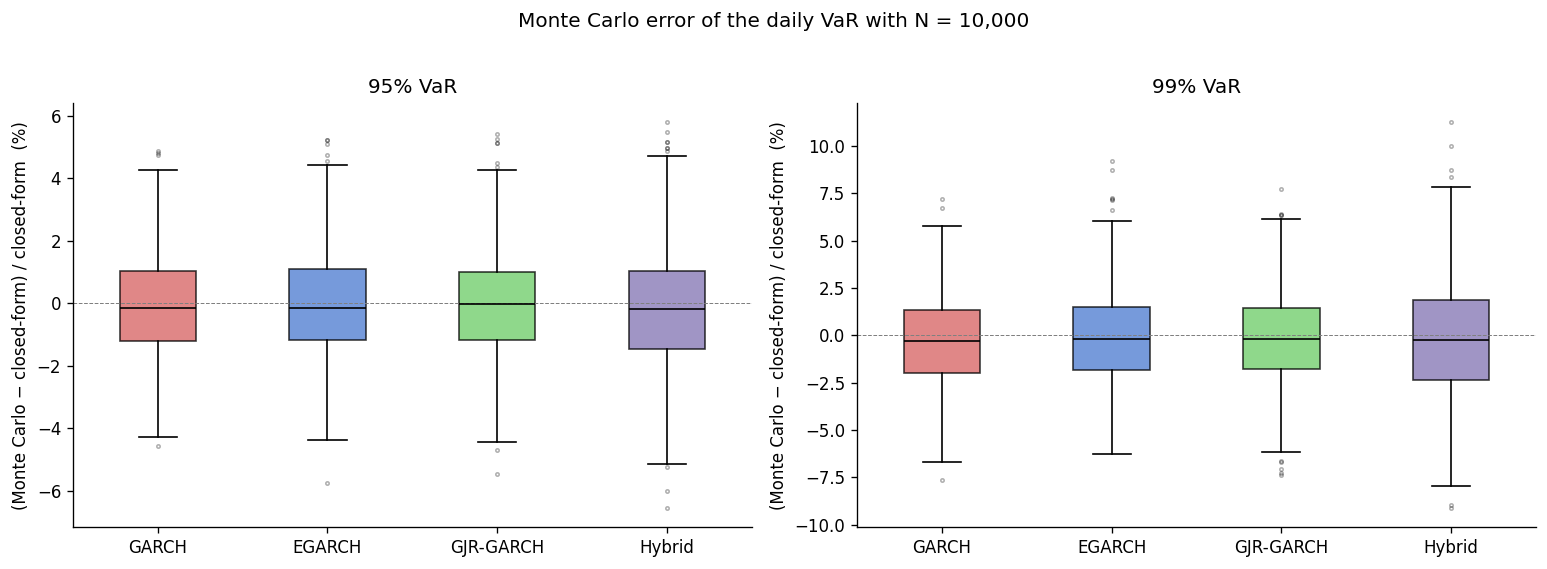

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, cl in zip(axes, CONF_LEVELS):
    data = [((mc_var[(m, cl)] - analytic_var(m, cl)) / analytic_var(m, cl) * 100).values for m in MODEL_NAMES]
    bp = ax.boxplot(data, tick_labels=MODEL_NAMES, patch_artist=True, medianprops=dict(color='black'),
                    flierprops=dict(marker='o', ms=2, alpha=0.3))
    for patch, m in zip(bp['boxes'], MODEL_NAMES):
        patch.set_facecolor(COLORS[m]); patch.set_alpha(0.75)
    ax.axhline(0, color='grey', lw=0.6, ls='--')
    ax.set_ylabel('(Monte Carlo − closed-form) / closed-form  (%)')
    ax.set_title(f'{cl:.0%} VaR')
plt.suptitle(f'Monte Carlo error of the daily VaR with N = {N_SIM:,}', y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'mc_var_error_boxplot.png', bbox_inches='tight')
plt.show()


## 10. Export

Everything is written to new files with an `mc_` prefix, so the outputs of the existing notebook are left exactly as they were.

In [23]:
daily = pd.DataFrame(index=EVAL_IDX)
daily['actual_next_ret'] = actual
for m in MODEL_NAMES:
    for cl in CONF_LEVELS:
        tag = int(cl * 100)
        daily[f'{m}_mc_var_{tag}']   = mc_var[(m, cl)]
        daily[f'{m}_mc_es_{tag}']    = mc_es[(m, cl)]
        daily[f'{m}_closed_var_{tag}'] = analytic_var(m, cl)
daily.to_csv(RESULTS_DIR / 'mc_daily_var_es.csv')

backtest_mc.set_index(['Model', 'CL', 'Method']).to_csv(RESULTS_DIR / 'mc_var_backtest_summary.csv')
multiday.to_csv(RESULTS_DIR / 'mc_multiday_var.csv', index=False)
multiday_summary.to_csv(TABLES_DIR / 'mc_multiday_summary.csv')

for path in sorted(list(RESULTS_DIR.glob('mc_*')) + list(TABLES_DIR.glob('mc_*'))):
    print(f"{path.parent.name}/{path.name:40s} {path.stat().st_size / 1024:8.1f} KB")


results/mc_daily_var_es.csv                         411.0 KB
results/mc_multiday_var.csv                          40.2 KB
results/mc_var_backtest_summary.csv                   2.3 KB
tables/mc_convergence.csv                            1.0 KB
tables/mc_multiday_summary.csv                       0.6 KB
tables/mc_pit_ks_tests.csv                           0.6 KB
tables/mc_sample_size_sensitivity.csv                1.4 KB
tables/mc_tail_assumption_comparison.csv             3.5 KB
tables/mc_var_vs_analytic.csv                        1.1 KB


## 11. Discussion

**Simulation reproduces the closed-form VaR, up to Monte Carlo error.** With 10,000 draws per day the simulated VaR differs from the closed-form figure by 1.3–1.5% on average at the 95% level (2.6–2.9 bp) and by 1.9–2.5% at the 99% level (6–8 bp), which is what the convergence study predicts for a Student-t with $\nu \approx 6$ (relative RMSE of 1.6% and 2.5% at $N = 10{,}000$, falling as $N^{-1/2}$). At 1,000 draws the error is 5–8% and the 99% Expected Shortfall error is 10%, so $N \ge 10{,}000$ is a sensible minimum for a 99% figure and 100,000 draws are needed to bring the 99% VaR error under 1%. Violation rates move by at most 0.25 percentage points between the two methods, and no Kupiec verdict changes.

**The independence tests are much less stable than the VaR figures.** The Christoffersen p-value of the GARCH model at 99% falls from 0.032 to 0.0008 when Monte Carlo noise adds a single violation (6 to 7); EGARCH at 95% moves from 0.032 to 0.050 and GJR-GARCH at 99% from 0.084 to 0.046. At 99% the test rests on 6–11 violations in 804 days, so a few basis points of simulation error are enough to change the verdict at the 5% level. Differences in Christoffersen p-values at the 99% level should therefore not be read as sharp.

**Which parts of the existing comparison are robust.** The Hybrid model's Christoffersen p-value lies between 0.65 and 0.89 in every setting tried (both confidence levels, closed-form and simulated, and all three innovation distributions), so the absence of violation clustering for the Hybrid model is robust. The GARCH-family failures are not: at 95% they sit at the edge of the 5% threshold (p between 0.032 and 0.055 across closed-form, simulated and common-tail variants, with GARCH at 0.055 and EGARCH at 0.050 under a common tail), and at 99% only GARCH is rejected under a common tail (p = 0.001), while EGARCH and GJR-GARCH pass (p = 0.084). The statement that the Hybrid is the only model to pass the independence test at both levels holds for the tail assumptions used in the existing notebook, but it is weaker under a common tail. What the evidence supports is that the Hybrid's violations show no sign of clustering, while the GARCH-family models' violations are borderline to clustered.

**The tail assumption matters for the violation-rate comparison.** The existing pipeline applies $\nu = 4$ to the Hybrid model but each GARCH model's own fitted $\nu$ (6.1–6.4). The 95% quantile multiplier is 1.507 at $\nu = 4$ and 1.591 at $\nu = 6.26$, a 5% difference that raises the Hybrid's 95% violation rate from 4.48% (common tail) to 5.22%. Under the common tail the Hybrid is still the closest to the 5% target (4.48% against 3.23% for GARCH, 3.98% for GJR-GARCH and 4.10% for EGARCH), but by a smaller margin, and its Kupiec p-value drops from 0.77 to 0.49. A Normal assumption raises every model's Expected Shortfall ratio at 99% to 1.22–1.26, that is, it understates the severity of tail losses by roughly a quarter. When the models are compared, the tail assumption should be the same across models or reported alongside.

**Density calibration.** The probability integral transform shows that the GARCH model is too wide: only 3.1% and 2.9% of realised returns fall in the outer 5% of its simulated distribution on the lower and upper side, and the Kolmogorov–Smirnov test rejects uniformity (p = 0.002). EGARCH (p = 0.044) and GJR-GARCH (p = 0.022) are rejected marginally, and the Hybrid model is not (p = 0.150). These p-values are indicative only, because PIT values from a volatility model need not be independent.

**Ten-day horizon.** Over ten days the simulated path VaR is 3–6% larger than the square-root-of-time figure for GARCH but 13–19% larger for EGARCH and GJR-GARCH (mean ratios of 1.13–1.19): the asymmetric models generate fatter multi-day tails than a rescaled one-day figure implies. Realised coverage is too thin to separate the two approaches: 1–4 violations in 80 non-overlapping windows against 4 expected at 95% and 0.8 at 99%. The finding is the difference in level, not in coverage.

**Limitations.** At a one-day horizon the simulation samples a distribution that is already known in closed form, so it adds no information beyond Monte Carlo error; its value lies in multi-day horizons, path-dependent quantities and non-standard innovation distributions. The Hybrid model is not simulated over ten days, because doing so requires recursive LSTM forecasts. Finally, the saved EGARCH volatilities contain a small amount of simulation noise from `arch`'s multi-step forecast, which is not seeded in `Model Development.ipynb`: re-running that notebook regenerates them slightly differently (EGARCH 95% violations changed from 32 to 31 between two executions), and the EGARCH rows here follow the saved file.